# 51. Semi-final — 제품·불량별 최선 방법 학습 · labeled 결과 · unlabeled 일반화 점검

| 제품 | 불량 | 최선 방법 | 학습 라벨 | 근거 |
|---|---|---|---|---|
| CN7 | 미성형 | 최종 모델 경보 (pct≥0.999) | 0개 | 3/4, 48번 I1 재료부족 Holm p 0.048, 47번 물리 일치 |
| CN7 | 가스 | 경보 + std4 순위, 운영 시 불량 발견 → 앞뒤 5샷 확장 | 0개 | 49번 5 → 8/15 (⚠ R1 한 에피소드, 사례) |
| RG3 | 가스 | 가스 RF (직전 10샷 std 24개) | labeled | 순열 p 0.007, 시간 순 학습(49b)에서도 유지 |
| RG3 | 미성형 | N1 + 가스 RF와 예산 나누기(68:32) / 참고: BOCPD·std4 경보(라벨 없음, 5/8 · 검사 ~21%) | labeled + unlabeled | N1 3/8 (우연 수준에 가까움) |

**가스+미성형(혼합) 처리**: `SF.GAS_INCLUDES_MIXED = True`(기본) → 혼합 샷을 **가스에도 셈**(가스·미성형 양쪽, 불량 총수는 그대로) + RG3 가스 RF 학습에서도 가스 양성으로 사용. CN7 가스 11 → 13. `False`면 예전처럼 미성형으로만

**평가 틀 2개를 나란히** — 표마다 `평가 틀` 열
- `2차` : 공식 2차 데이터 샷만 평가 (RG3 지도 모델은 **학습도 2차 샷만**) + 공식 2차 **행(LH/RH) 단위** 표 추가
- `전체`: 1차 + 2차 labeled 전체
- 초기허용불량·RG3 R6 제외는 두 틀 공통

`SF.SHORT_RG3` = `'N1'`(기본) / `'BOCPD_std4'` / `'S1_ewma_std4'` 로 RG3 미성형 모델 교체 가능
실행 시간: [A] 2개 틀 × 수 분, [B] 1분, [C] 제품당 수 분

In [1]:
import pandas as pd
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 40); pd.set_option('display.max_rows', 300)
%load_ext autoreload
%autoreload 2
import semi_final as SF
# SF.GAS_INCLUDES_MIXED = False   # 예전 방식(혼합 = 미성형만)과 비교할 때
# SF.SHORT_RG3 = 'BOCPD_std4'
R = SF.run_labeled(frames=('2차', '전체'), seeds=(0, 1, 2))

[2차] 2차 데이터만 (공식 평가 대상 샷 — RG3 지도 모델은 학습도 2차 샷만)
  [2차] cn7 완료
  [2차] rg3 seed 0 완료
  [2차] rg3 seed 1 완료
  [2차] rg3 seed 2 완료
[전체] 1차 + 2차 labeled 전체
  [전체] cn7 완료
  [전체] rg3 seed 0 완료
  [전체] rg3 seed 1 완료
  [전체] rg3 seed 2 완료


## [A-1] 최선 방법 요약 — 2차 vs 전체 나란히 (검사 10%, 시드 평균)

In [2]:
display(R['compare'].round(3))

,제품,불량,방법,기준 [2차],잡은 수 [2차],Precision [2차],Recall(해당 유형) [2차],기준 [전체],잡은 수 [전체],Precision [전체],Recall(해당 유형) [전체]
0,CN7,가스,경보 + std4 순위 / 운영: + 주변 5샷 확장,검사 10% (61샷),5/13 → 확장 시 7/13,0.098,0.385,검사 10% (198샷),7/13 → 확장 시 7/13,0.040,0.538
1,CN7,미성형,최종 모델 경보 (pct≥0.999),경보 5샷,3/3,0.600,1.000,경보 8샷,3/4,0.375,0.750
2,RG3,가스,가스 RF (LORO),검사 10% (60샷),7.7/17,0.156,0.451,검사 10% (60샷),7.7/17,0.156,0.451
3,RG3,가스,가스 RF (시간 순 학습),검사 10% (60샷),5.3/17,0.139,0.314,검사 10% (60샷),5.3/17,0.139,0.314
4,RG3,가스+미성형,가스 RF(LORO) + N1 (g=0.68),검사 10% (60샷),가스 6.0/17 · 미성형 3.0/8,0.150,0.360,검사 10% (60샷),가스 6.0/17 · 미성형 3.0/8,0.150,0.360
5,RG3,미성형,"BOCPD·std4 경보 (라벨 없음, 참고)",경보 123샷,5/8,0.065,0.625,경보 123샷,5/8,0.065,0.625
6,RG3,미성형,N1 단독,검사 10% (60샷),3.0/8,0.117,0.375,검사 10% (60샷),3.0/8,0.117,0.375


In [3]:
for fr in ('2차', '전체'):
    print(f'===== {fr}')
    display(R['best'][R['best']['평가 틀'] == fr].drop(columns='평가 틀').round(3))

===== 2차


,제품,불량,방법,기준,잡은 수,Precision,Recall(해당 유형),학습 라벨,신뢰성
0,CN7,미성형,최종 모델 경보 (pct≥0.999),경보 5샷,3/3,0.600,1.000,0개,R1 한 에피소드(3샷 연속) · 48번 I1 Holm p 0.048 · 47번 물...
1,CN7,가스,경보 + std4 순위 / 운영: + 주변 5샷 확장,검사 10% (61샷),5/13 → 확장 시 7/13,0.098,0.385,0개,가스가 모두 R1 → 검증 불가(사례)
2,RG3,가스,가스 RF (LORO),검사 10% (60샷),7.7/17,0.156,0.451,labeled (다른 Run),순열 p 0.007 · 시드 안정 · 날짜 상관 ρ 0.50
3,RG3,가스,가스 RF (시간 순 학습),검사 10% (60샷),5.3/17,0.139,0.314,이전 Run만,"현장 조건 (미래 라벨 없음, 49b)"
4,RG3,미성형,N1 단독,검사 10% (60샷),3.0/8,0.117,0.375,labeled + unlabeled(정상),50번 보정p 0.072~0.32 → 우연 수준 못 벗어남
5,RG3,미성형,"BOCPD·std4 경보 (라벨 없음, 참고)",경보 123샷,5/8,0.065,0.625,0개,"46번 전체 탐색 보정 p 0.013 · 단, 경보율이 목표의 2~3배(검사 ~21%)"
6,RG3,가스+미성형,가스 RF(LORO) + N1 (g=0.68),검사 10% (60샷),가스 6.0/17 · 미성형 3.0/8,0.150,0.360,labeled,43번 순열 결과 참고


===== 전체


,제품,불량,방법,기준,잡은 수,Precision,Recall(해당 유형),학습 라벨,신뢰성
7,CN7,미성형,최종 모델 경보 (pct≥0.999),경보 8샷,3/4,0.375,0.750,0개,R1 한 에피소드(3샷 연속) · 48번 I1 Holm p 0.048 · 47번 물...
8,CN7,가스,경보 + std4 순위 / 운영: + 주변 5샷 확장,검사 10% (198샷),7/13 → 확장 시 7/13,0.040,0.538,0개,가스가 모두 R1 → 검증 불가(사례)
9,RG3,가스,가스 RF (LORO),검사 10% (60샷),7.7/17,0.156,0.451,labeled (다른 Run),순열 p 0.007 · 시드 안정 · 날짜 상관 ρ 0.50
10,RG3,가스,가스 RF (시간 순 학습),검사 10% (60샷),5.3/17,0.139,0.314,이전 Run만,"현장 조건 (미래 라벨 없음, 49b)"
11,RG3,미성형,N1 단독,검사 10% (60샷),3.0/8,0.117,0.375,labeled + unlabeled(정상),50번 보정p 0.072~0.32 → 우연 수준 못 벗어남
12,RG3,미성형,"BOCPD·std4 경보 (라벨 없음, 참고)",경보 123샷,5/8,0.065,0.625,0개,"46번 전체 탐색 보정 p 0.013 · 단, 경보율이 목표의 2~3배(검사 ~21%)"
13,RG3,가스+미성형,가스 RF(LORO) + N1 (g=0.68),검사 10% (60샷),가스 6.0/17 · 미성형 3.0/8,0.150,0.360,labeled,43번 순열 결과 참고


## [A-2] 경보 규칙 (CN7 미성형 · RG3 미성형 BOCPD) — 경보 샷 기준

In [4]:
display(R['rules'][['평가 틀', '방법', '경보(검사) 샷', '불량', '가스', '미성형', 'Precision', 'Recall', 'F1', '불량 없는 Run 경보율']].round(3))

,평가 틀,방법,경보(검사) 샷,불량,가스,미성형,Precision,Recall,F1,불량 없는 Run 경보율
0,2차,CN7 미성형 | 최종 모델 경보 pct≥0.999,5,3/14,2/13,3/3,0.600,0.214,0.316,0.005
1,2차,"CN7 미성형 | I1 재료부족 규칙(경보율 1%, 물리 설명용)",19,3/14,2/13,3/3,0.158,0.214,0.182,0.019
2,2차,CN7 미성형 | 경보 AND I1 (둘 다),5,3/14,2/13,3/3,0.600,0.214,0.316,0.005
3,2차,"RG3 미성형 | BOCPD·std4 경보 (정상 기준 10%, 실제 경보율은 더 높음)",123,8/25,3/17,5/8,0.065,0.320,0.108,0.244
4,전체,CN7 미성형 | 최종 모델 경보 pct≥0.999,8,3/15,2/13,3/4,0.375,0.200,0.261,0.003
5,전체,"CN7 미성형 | I1 재료부족 규칙(경보율 1%, 물리 설명용)",50,3/15,2/13,3/4,0.060,0.200,0.092,0.020
6,전체,CN7 미성형 | 경보 AND I1 (둘 다),5,3/15,2/13,3/4,0.600,0.200,0.300,0.002
7,전체,"RG3 미성형 | BOCPD·std4 경보 (정상 기준 10%, 실제 경보율은 더 높음)",123,8/25,3/17,5/8,0.065,0.320,0.108,0.244


## [A-3] 검사 비율별 (5·10·15%) — 샷 단위

In [5]:
display(R['curves'].round(3))

,평가 틀,제품,모델,검사 비율,불량 수,가스 수,미성형 수,불량 전체,가스 전체,미성형 전체,Precision,Recall,F1,정규화 Precision,검사 샷
0,2차,cn7,CN7 | 경보 먼저 + std4 순위,5%,3.000,2.000,3.000,14,13,3,0.097,0.214,0.133,0.214,31
1,2차,cn7,CN7 | 경보 먼저 + std4 순위,10%,6.000,5.000,3.000,14,13,3,0.098,0.429,0.160,0.429,61
2,2차,cn7,CN7 | 경보 먼저 + std4 순위,15%,8.000,7.000,3.000,14,13,3,0.088,0.571,0.152,0.571,91
3,2차,rg3,RG3 가스 | 가스 RF (LORO),5%,5.667,4.333,1.333,25,17,8,0.189,0.227,0.206,0.227,30
4,2차,rg3,RG3 가스 | 가스 RF (LORO),10%,9.333,7.667,1.667,25,17,8,0.156,0.373,0.220,0.373,60
5,2차,rg3,RG3 가스 | 가스 RF (LORO),15%,10.000,8.000,2.000,25,17,8,0.112,0.400,0.175,0.400,89
6,2차,rg3,RG3 가스 | 가스 RF (시간 순 학습),5%,7.667,5.000,2.667,25,17,8,0.256,0.307,0.279,0.307,30
7,2차,rg3,RG3 가스 | 가스 RF (시간 순 학습),10%,8.333,5.333,3.000,25,17,8,0.139,0.333,0.196,0.333,60
8,2차,rg3,RG3 가스 | 가스 RF (시간 순 학습),15%,8.667,5.667,3.000,25,17,8,0.097,0.347,0.152,0.347,89
9,2차,rg3,RG3 미성형 | N1 단독,5%,4.667,2.667,2.000,25,17,8,0.156,0.187,0.170,0.187,30


## [A-3b] 공식 2차 '행'(LH/RH) 단위 — 대회 공식 평가 형태 (2차 틀만)

In [6]:
display(R['rows_curves'].round(3))

,평가 틀,제품,모델,검사 비율,불량 수,가스 수,미성형 수,불량 전체,가스 전체,미성형 전체,Precision,Recall,F1,정규화 Precision,검사 샷
0,2차,cn7,CN7 | 경보 먼저 + std4 순위,5%,6.000,2.000,4.000,17,13,4,0.098,0.353,0.154,0.353,61
1,2차,cn7,CN7 | 경보 먼저 + std4 순위,10%,9.000,5.000,4.000,17,13,4,0.074,0.529,0.129,0.529,122
2,2차,cn7,CN7 | 경보 먼저 + std4 순위,15%,11.000,7.000,4.000,17,13,4,0.060,0.647,0.111,0.647,182
3,2차,cn7,CN7 | 최종 모델 점수 (참고),5%,6.000,2.000,4.000,17,13,4,0.098,0.353,0.154,0.353,61
4,2차,cn7,CN7 | 최종 모델 점수 (참고),10%,8.000,4.000,4.000,17,13,4,0.066,0.471,0.115,0.471,122
5,2차,cn7,CN7 | 최종 모델 점수 (참고),15%,8.000,4.000,4.000,17,13,4,0.044,0.471,0.080,0.471,182
6,2차,rg3,RG3 가스 | 가스 RF (LORO),5%,5.667,4.333,1.333,25,17,8,0.094,0.227,0.133,0.227,60
7,2차,rg3,RG3 가스 | 가스 RF (LORO),10%,9.333,7.667,1.667,25,17,8,0.078,0.373,0.130,0.373,119
8,2차,rg3,RG3 가스 | 가스 RF (LORO),15%,10.000,8.000,2.000,25,17,8,0.056,0.400,0.099,0.400,178
9,2차,rg3,RG3 가스 | 가스 RF (시간 순 학습),5%,7.667,5.000,2.667,25,17,8,0.128,0.307,0.180,0.307,60


## [A-4] 검사 비율과 무관한 분류 지표 (R-Precision · ROC-AUC · AP)

In [7]:
display(R['rank'].round(3))

,평가 틀,제품,모델,seed,불량 수,R-Precision,ROC-AUC,AP,무작위 기준(불량률),Precision@Recall25%,Recall25% 필요 검사 비율,Precision@Recall50%,Recall50% 필요 검사 비율,Precision@Recall75%,Recall75% 필요 검사 비율
0,2차,cn7,CN7 | 경보 먼저 + std4 순위,0.0,14.0,0.214,0.708,0.265,0.023,0.105,0.063,0.106,0.109,0.030,0.614
1,2차,rg3,RG3 가스 | 가스 RF (LORO),1.0,25.0,0.160,0.629,0.119,0.042,0.203,0.060,0.058,0.383,0.053,0.606
2,2차,rg3,RG3 가스 | 가스 RF (시간 순 학습),1.0,25.0,0.293,0.625,0.157,0.042,0.338,0.036,0.064,0.347,0.049,0.657
3,2차,rg3,RG3 미성형 | N1 단독,1.0,25.0,0.107,0.611,0.102,0.042,0.162,0.074,0.084,0.262,0.046,0.693
4,전체,cn7,CN7 | 경보 먼저 + std4 순위,0.0,15.0,0.200,0.736,0.220,0.008,0.051,0.040,0.046,0.088,0.011,0.544
5,전체,rg3,RG3 가스 | 가스 RF (LORO),1.0,25.0,0.160,0.629,0.119,0.042,0.203,0.060,0.058,0.383,0.053,0.606
6,전체,rg3,RG3 가스 | 가스 RF (시간 순 학습),1.0,25.0,0.293,0.625,0.157,0.042,0.338,0.036,0.064,0.347,0.049,0.657
7,전체,rg3,RG3 미성형 | N1 단독,1.0,25.0,0.107,0.611,0.102,0.042,0.162,0.074,0.084,0.262,0.046,0.693


## [A-5] 운영 루프 (100샷 묶음마다 10% 검사)

In [8]:
display(R['operation'].round(3))

,평가 틀,제품,기본 점수,전략,seed,검사 샷,찾은 불량,전체 불량,Precision,Recall,F1,가스,가스 전체,미성형,미성형 전체
0,2차,cn7,CN7 경보+std4,S1 고정 순위,0,61,5,14,0.082,0.357,0.133,4,13,3,3
1,2차,cn7,CN7 경보+std4,S2 고정 + 주변 확장,0,61,8,14,0.131,0.571,0.213,7,13,3,3
2,2차,rg3,RG3 가스 RF(시간 순),S1 고정 순위,0,62,8,25,0.129,0.320,0.184,5,17,3,8
3,2차,rg3,RG3 가스 RF(시간 순),S2 고정 + 주변 확장,0,62,7,25,0.113,0.280,0.161,4,17,3,8
4,전체,cn7,CN7 경보+std4,S1 고정 순위,0,199,5,15,0.025,0.333,0.047,4,13,3,4
5,전체,cn7,CN7 경보+std4,S2 고정 + 주변 확장,0,199,8,15,0.040,0.533,0.075,7,13,3,4
6,전체,rg3,RG3 가스 RF(시간 순),S1 고정 순위,0,62,8,25,0.129,0.320,0.184,5,17,3,8
7,전체,rg3,RG3 가스 RF(시간 순),S2 고정 + 주변 확장,0,62,7,25,0.113,0.280,0.161,4,17,3,8


## [B] 배포용 학습 — labeled 전체로 최종 학습해 저장
- CN7: 라벨을 쓰지 않는 규칙 → 최종 모델 + std4 정상 기준만
- RG3: 가스 RF, N1을 labeled 전체(+ unlabeled 3,000샷 정상)로 학습 → `outputs/semi_final/deploy_rg3.pkl`

In [9]:
P = SF.fit_deploy(seed=0)

[cn7] 배포용 학습 저장 → ./outputs/semi_final/deploy_cn7.pkl
[rg3] 배포용 학습 저장 → ./outputs/semi_final/deploy_rg3.pkl


## [C] unlabeled 일반화 점검
unlabeled에는 샷 라벨이 없음 → 할 수 있는 정직한 점검 3가지
1. **날짜별 약한 라벨**: ERR_FACT_QTY로 만든 날짜별 불량률 vs 규칙의 날짜별 경보율·평균 점수 (Spearman + 순열 p). **'labeled 날짜 제외'가 진짜 독립 검증**
2. **월별 경보율 안정성**: 정상 기준에서 정한 경보율(0.1% · 5% · 10%)이 처음 보는 달에도 유지되나 (9~11월은 학습 기간)
3. **현장 부담**: 하루 경보 샷 수

In [10]:
U = SF.unlabeled_check(P, products=('cn7', 'rg3'), min_shots=100, n_perm=5000)

[cn7] unlabeled 10,605샷 · 비교 날짜 15일 (labeled 날짜 3일)
[rg3] unlabeled 16,054샷 · 비교 날짜 21일 (labeled 날짜 3일)


### 1) 날짜별 경보율·점수 vs 불량률

In [11]:
C = U['corr']
display(C[C['날짜 범위'] == 'labeled 날짜 제외'].round(3))
display(C[C['날짜 범위'] == '전체 날짜'].round(3))

,제품,날짜 범위,x (날짜별),날짜 수,Spearman ρ,순열 p(양측)
0,cn7,labeled 날짜 제외,경보율|최종 모델 경보 (pct≥0.999),12,-0.508,0.093
1,cn7,labeled 날짜 제외,경보율|std4 흔들림 (pct≥0.95),12,-0.042,0.901
2,cn7,labeled 날짜 제외,경보율|경보 or std4 (CN7 가스 규칙),12,-0.042,0.901
3,cn7,labeled 날짜 제외,최종 모델 pct 평균,12,-0.287,0.367
4,cn7,labeled 날짜 제외,std4 pct 평균,12,0.175,0.592
10,rg3,labeled 날짜 제외,경보율|최종 모델 경보 (pct≥0.999),18,-0.013,0.959
11,rg3,labeled 날짜 제외,경보율|std4 흔들림 (pct≥0.95),18,0.617,0.007
12,rg3,labeled 날짜 제외,경보율|경보 or std4 (CN7 가스 규칙),18,0.622,0.007
13,rg3,labeled 날짜 제외,경보율|가스 RF 상위 10%,18,0.765,0.000
14,rg3,labeled 날짜 제외,경보율|N1 상위 10%,18,0.930,0.000


,제품,날짜 범위,x (날짜별),날짜 수,Spearman ρ,순열 p(양측)
5,cn7,전체 날짜,경보율|최종 모델 경보 (pct≥0.999),15,-0.385,0.165
6,cn7,전체 날짜,경보율|std4 흔들림 (pct≥0.95),15,0.046,0.876
7,cn7,전체 날짜,경보율|경보 or std4 (CN7 가스 규칙),15,0.046,0.876
8,cn7,전체 날짜,최종 모델 pct 평균,15,-0.346,0.209
9,cn7,전체 날짜,std4 pct 평균,15,0.146,0.603
19,rg3,전체 날짜,경보율|최종 모델 경보 (pct≥0.999),21,0.167,0.472
20,rg3,전체 날짜,경보율|std4 흔들림 (pct≥0.95),21,0.656,0.002
21,rg3,전체 날짜,경보율|경보 or std4 (CN7 가스 규칙),21,0.669,0.001
22,rg3,전체 날짜,경보율|가스 RF 상위 10%,21,0.522,0.019
23,rg3,전체 날짜,경보율|N1 상위 10%,21,0.528,0.016


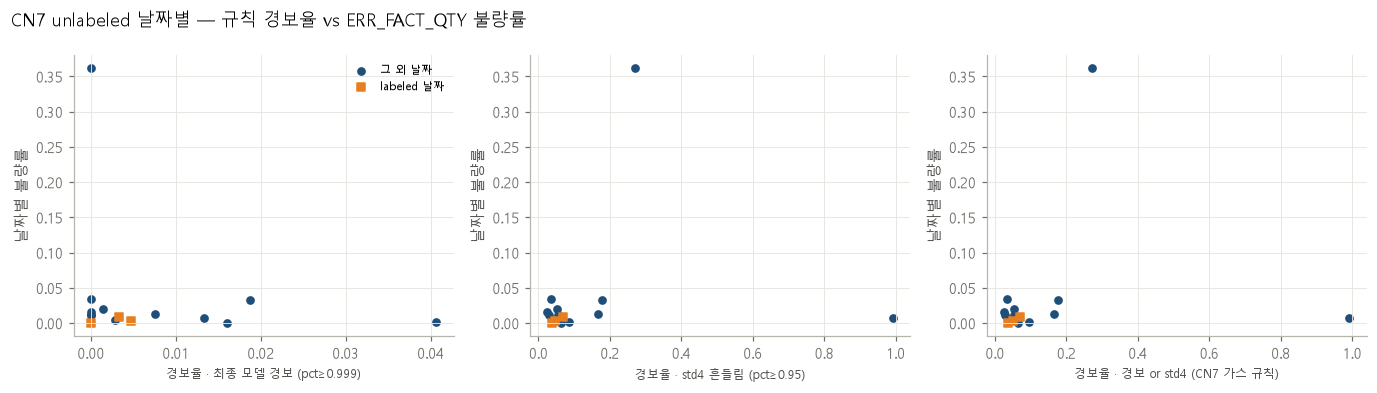

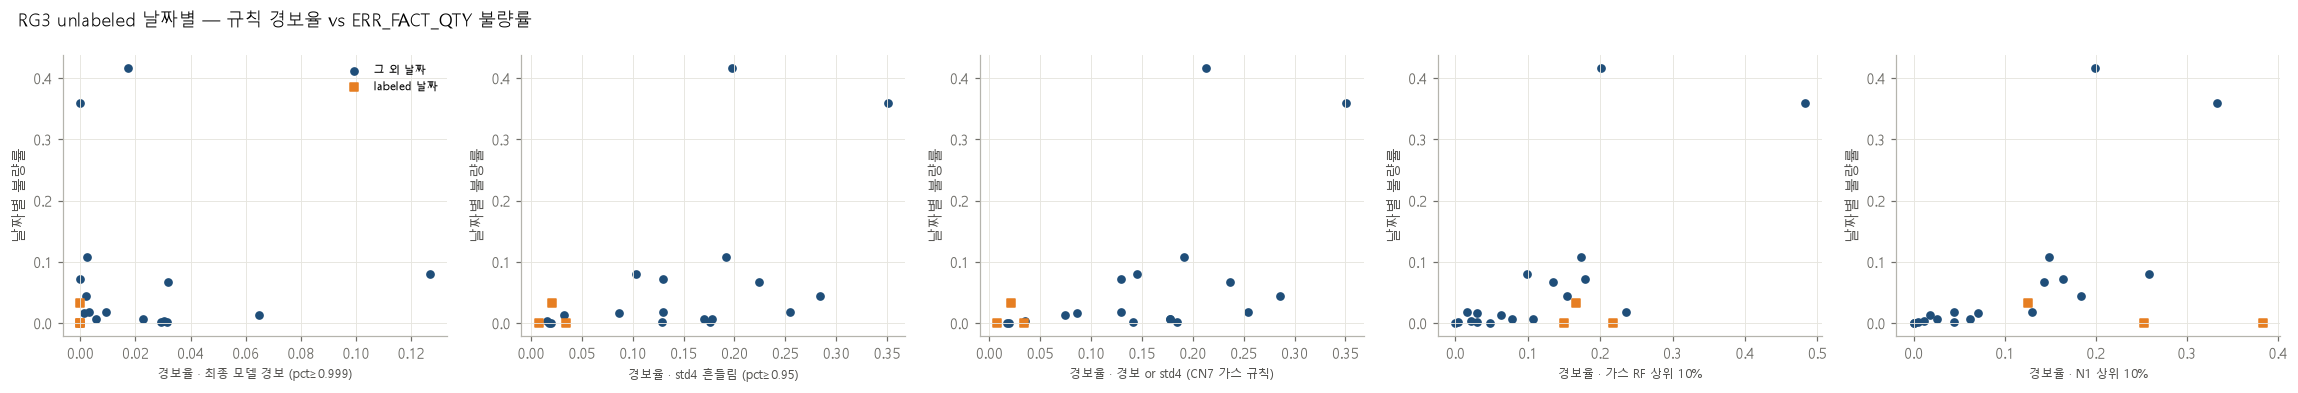

In [12]:
SF.plot_daily(U, 'cn7')
SF.plot_daily(U, 'rg3')

### 2) 월별 경보율 (정상기준기간_비율 = 그 달 샷 중 학습 기간 비율 → 0이면 처음 보는 달)

In [13]:
display(U['monthly'].round(4))

,제품,month,샷,정상기준기간_비율,최종 모델 경보 (pct≥0.999),std4 흔들림 (pct≥0.95),경보 or std4 (CN7 가스 규칙),가스 RF 상위 10%,N1 상위 10%
0,cn7,2020-03,8,0.0,0.0000,0.0000,0.0000,NaN,NaN
1,cn7,2020-04,1301,0.0,0.0123,0.9301,0.9301,NaN,NaN
2,cn7,2020-05,591,0.0,0.0406,0.0846,0.0964,NaN,NaN
3,cn7,2020-07,653,0.0,0.0031,0.0750,0.0750,NaN,NaN
4,cn7,2020-08,391,0.0,0.0077,0.0793,0.0793,NaN,NaN
5,cn7,2020-09,1354,1.0,0.0037,0.1263,0.1263,NaN,NaN
6,cn7,2020-10,6307,1.0,0.0021,0.0533,0.0539,NaN,NaN
7,rg3,2020-03,2041,0.0,0.0122,0.2636,0.2695,0.1671,0.1930
8,rg3,2020-04,2568,0.0,0.0218,0.1569,0.1636,0.0545,0.0331
9,rg3,2020-05,21,0.0,0.0000,0.0000,0.0000,0.0000,0.0000


### 3) 날짜별 표 (생산 샷 · 불량 수 · 규칙별 경보율)

In [14]:
for p in ('cn7', 'rg3'):
    display(U['days'][p].round(4).head(40))

,n,labeled_day,ref_period,경보율|최종 모델 경보 (pct≥0.999),경보율|std4 흔들림 (pct≥0.95),경보율|경보 or std4 (CN7 가스 규칙),최종 모델 pct 평균,std4 pct 평균,err,불량률
plan_date,,,,,,,,,,
2020-03-24,8,False,0.0,0.0000,0.0000,0.0000,0.0009,0.0081,321.0,20.0625
2020-04-01,86,False,0.0,0.0000,0.1860,0.1860,0.6237,0.6064,250.0,1.4535
2020-04-03,16,False,0.0,0.0000,0.3125,0.3125,0.3688,0.3754,193.0,6.0312
2020-04-04,1198,False,0.0,0.0134,0.9925,0.9925,0.4328,0.9938,17.0,0.0071
2020-04-06,1,False,0.0,0.0000,0.0000,0.0000,0.0012,0.0081,203.0,101.5000
2020-05-27,590,False,0.0,0.0407,0.0847,0.0966,0.9417,0.5431,2.0,0.0017
2020-05-28,1,False,0.0,0.0000,0.0000,0.0000,0.0012,0.0081,3.0,1.5000
2020-07-24,56,False,0.0,0.0000,0.2321,0.2321,0.4369,0.6485,100.0,0.8929
2020-07-28,12,False,0.0,0.0000,0.4167,0.4167,0.3096,0.4201,31.0,1.2917


,n,labeled_day,ref_period,경보율|최종 모델 경보 (pct≥0.999),경보율|std4 흔들림 (pct≥0.95),경보율|경보 or std4 (CN7 가스 규칙),경보율|가스 RF 상위 10%,경보율|N1 상위 10%,최종 모델 pct 평균,std4 pct 평균,가스 RF 점수 평균,N1 점수 평균,err,불량률
plan_date,,,,,,,,,,,,,,
2020-03-29,582,False,0.0,0.0172,0.1976,0.2131,0.2010,0.1993,0.4660,0.6727,0.1555,0.0592,485.0,0.4167
2020-03-30,1447,False,0.0,0.0021,0.2840,0.2861,0.1548,0.1838,0.7671,0.6896,0.1535,0.0572,126.0,0.0435
2020-03-31,12,False,0.0,1.0000,1.0000,1.0000,0.0000,1.0000,0.9998,0.9998,0.1503,0.1575,59.0,2.4583
2020-04-20,15,False,0.0,0.0000,0.0667,0.0667,0.0000,0.0000,0.1343,0.0913,0.0896,0.0067,15.0,0.5000
2020-04-21,69,False,0.0,0.0000,0.1884,0.1884,0.0580,0.0000,0.4945,0.6659,0.1462,0.0372,12.0,0.0870
2020-04-22,2,False,0.0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0021,0.0028,0.0836,0.0016,0.0,0.0000
2020-04-23,19,False,0.0,0.1053,0.1053,0.1053,0.0000,0.1053,0.2666,0.1077,0.0906,0.0180,83.0,2.1842
2020-04-24,582,False,0.0,0.0292,0.1289,0.1409,0.0034,0.0447,0.9796,0.5789,0.1291,0.0218,3.0,0.0026
2020-04-25,103,False,0.0,0.0000,0.0194,0.0194,0.0485,0.0000,0.3552,0.4050,0.1168,0.0125,0.0,0.0000


## 읽는 법
1. **[A-1]** 보고서 '최종 결과' 표의 초안. **2차(공식 평가 대상)와 전체가 크게 다르면** 그 이유(2차에 불량이 적음 · 학습 데이터 감소)를 같이 적기
2. **[C-1] labeled 날짜 제외 ρ > 0, 순열 p < 0.05** 인 규칙 → '처음 보는 날짜에서도 불량이 많은 날 경보가 많다' = 일반화 근거
   - 날짜 수가 적고(수~수십 일), ERR_FACT_QTY는 모든 유형 합계 → 강한 증거는 아님. ρ의 **방향**이 일관된지가 핵심
   - RG3 가스 RF·N1은 labeled로 학습 → labeled 날짜를 넣은 '전체 날짜' 결과는 누수가 섞여 있음 (참고만)
3. **[C-2]** 처음 보는 달에서 경보율이 목표보다 크게 높으면 → 기준 재보정 필요 (현장 적용 시 '월 1회 정상 기준 갱신' 제안 근거)
4. 일반화가 확인 안 돼도 그 자체가 결과: 'labeled 기간 밖으로의 일반화는 약한 라벨로는 확인되지 않음 → 현장 도입 시 초기 검증 기간 필요'